Import library

In [3]:
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
!pip install adjustText
from adjustText import adjust_text
df=pd.read_csv('seoul_air_quality_2022_english.csv')
df_raw=df.copy()
df.head(10)


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,datetime,station_code,district,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
0,1/1/2022 0:00,101,Jongno-gu,0.4,0.016,0.026,23.0,12.0,0.003,152211,23.91,6365,72524,72980,79231,1111000000,2022
1,1/1/2022 0:00,102,Jung-gu,0.4,0.024,0.016,25.0,10.0,0.003,130785,9.96,13131,63139,63377,67408,1114000000,2022
2,1/1/2022 0:00,103,Yongsan-gu,0.4,0.020,0.020,24.0,13.0,0.003,233284,21.87,10668,109805,113012,120272,1117000000,2022
3,1/1/2022 0:00,104,Eunpyeong-gu,0.8,0.019,0.019,19.0,10.0,0.004,470602,29.71,15838,213876,224163,246439,1138000000,2022
4,1/1/2022 0:00,105,Seodaemun-gu,0.7,0.020,0.019,23.0,13.0,NaN,319554,17.63,18129,145797,150094,169460,1141000000,2022
5,1/1/2022 0:00,106,Mapo-gu,0.4,0.026,0.014,18.0,6.0,0.002,375585,23.85,15745,180084,175006,200579,1144000000,2022
6,1/1/2022 0:00,107,Seongdong-gu,0.3,0.017,0.024,19.0,5.0,0.003,288234,16.82,17136,133305,139691,148543,1120000000,2022
7,1/1/2022 0:00,108,Gwangjin-gu,0.7,0.025,0.018,17.0,8.0,0.001,351252,17.06,20586,169291,168197,183055,1121500000,2022
8,1/1/2022 0:00,109,Dongdaemun-gu,0.4,0.021,0.022,16.0,11.0,0.002,353601,14.22,24873,169873,171903,181698,1123000000,2022
9,1/1/2022 0:00,110,Jungnang-gu,0.4,0.019,0.025,21.0,8.0,0.003,390140,18.50,21092,187413,191422,198718,1126000000,2022


Exploretary data analysis

In [4]:
print(df.shape)
df.info()
display(df.describe())
df.isnull().sum()
print((df.isnull().sum())*100/len(df))
#Check duplicated date
display(df.duplicated(subset=['district','datetime']).sum())


(216545, 17)
<class 'pandas.DataFrame'>
RangeIndex: 216545 entries, 0 to 216544
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   datetime            216545 non-null  str    
 1   station_code        216545 non-null  int64  
 2   district            216545 non-null  str    
 3   CO                  215142 non-null  float64
 4   NO2                 215540 non-null  float64
 5   O3                  215209 non-null  float64
 6   PM10                214136 non-null  float64
 7   PM2.5               214805 non-null  float64
 8   SO2                 214839 non-null  float64
 9   population          216545 non-null  int64  
 10  area_km2            216545 non-null  float64
 11  population_density  216545 non-null  int64  
 12  households          216545 non-null  int64  
 13  male_population     216545 non-null  int64  
 14  female_population   216545 non-null  int64  
 15  district_code       216545 non-n

,station_code,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
count,216545.000000,215142.000000,215540.000000,215209.000000,214136.000000,214805.000000,214839.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,216545.000000,2.165450e+05,216545.0
mean,113.006812,0.437070,0.020868,0.029275,32.861625,18.378618,0.002886,386814.131368,24.237395,16790.225316,177867.498377,187068.209924,199745.921444,1.141691e+09,2022.0
std,7.214851,0.185666,0.013388,0.019398,22.842114,13.907109,0.000843,122930.793712,9.121672,4603.200653,55573.744517,59252.031769,63846.926920,1.863222e+07,0.0
min,101.000000,0.100000,0.001000,0.000000,1.000000,1.000000,0.001000,130785.000000,9.960000,6365.000000,63139.000000,63377.000000,67408.000000,1.111000e+09,2022.0
25%,107.000000,0.300000,0.011000,0.015000,19.000000,9.000000,0.002000,313989.000000,17.410000,13862.000000,144313.000000,150094.000000,161814.000000,1.126000e+09,2022.0
50%,113.000000,0.400000,0.017000,0.027000,28.000000,15.000000,0.003000,390432.000000,23.600000,16951.000000,181187.000000,191422.000000,201821.000000,1.141000e+09,2022.0
75%,119.000000,0.500000,0.028000,0.040000,41.000000,24.000000,0.003000,464037.000000,29.570000,19616.000000,202169.000000,224163.000000,237062.000000,1.156000e+09,2022.0
max,125.000000,2.000000,0.096000,0.167000,482.000000,126.000000,0.016000,664514.000000,46.970000,25509.000000,284853.000000,319743.000000,344771.000000,1.174000e+09,2022.0


datetime              0.000000
station_code          0.000000
district              0.000000
CO                    0.647902
NO2                   0.464107
O3                    0.616962
PM10                  1.112471
PM2.5                 0.803528
SO2                   0.787827
population            0.000000
area_km2              0.000000
population_density    0.000000
households            0.000000
male_population       0.000000
female_population     0.000000
district_code         0.000000
year                  0.000000
dtype: float64


np.int64(0)

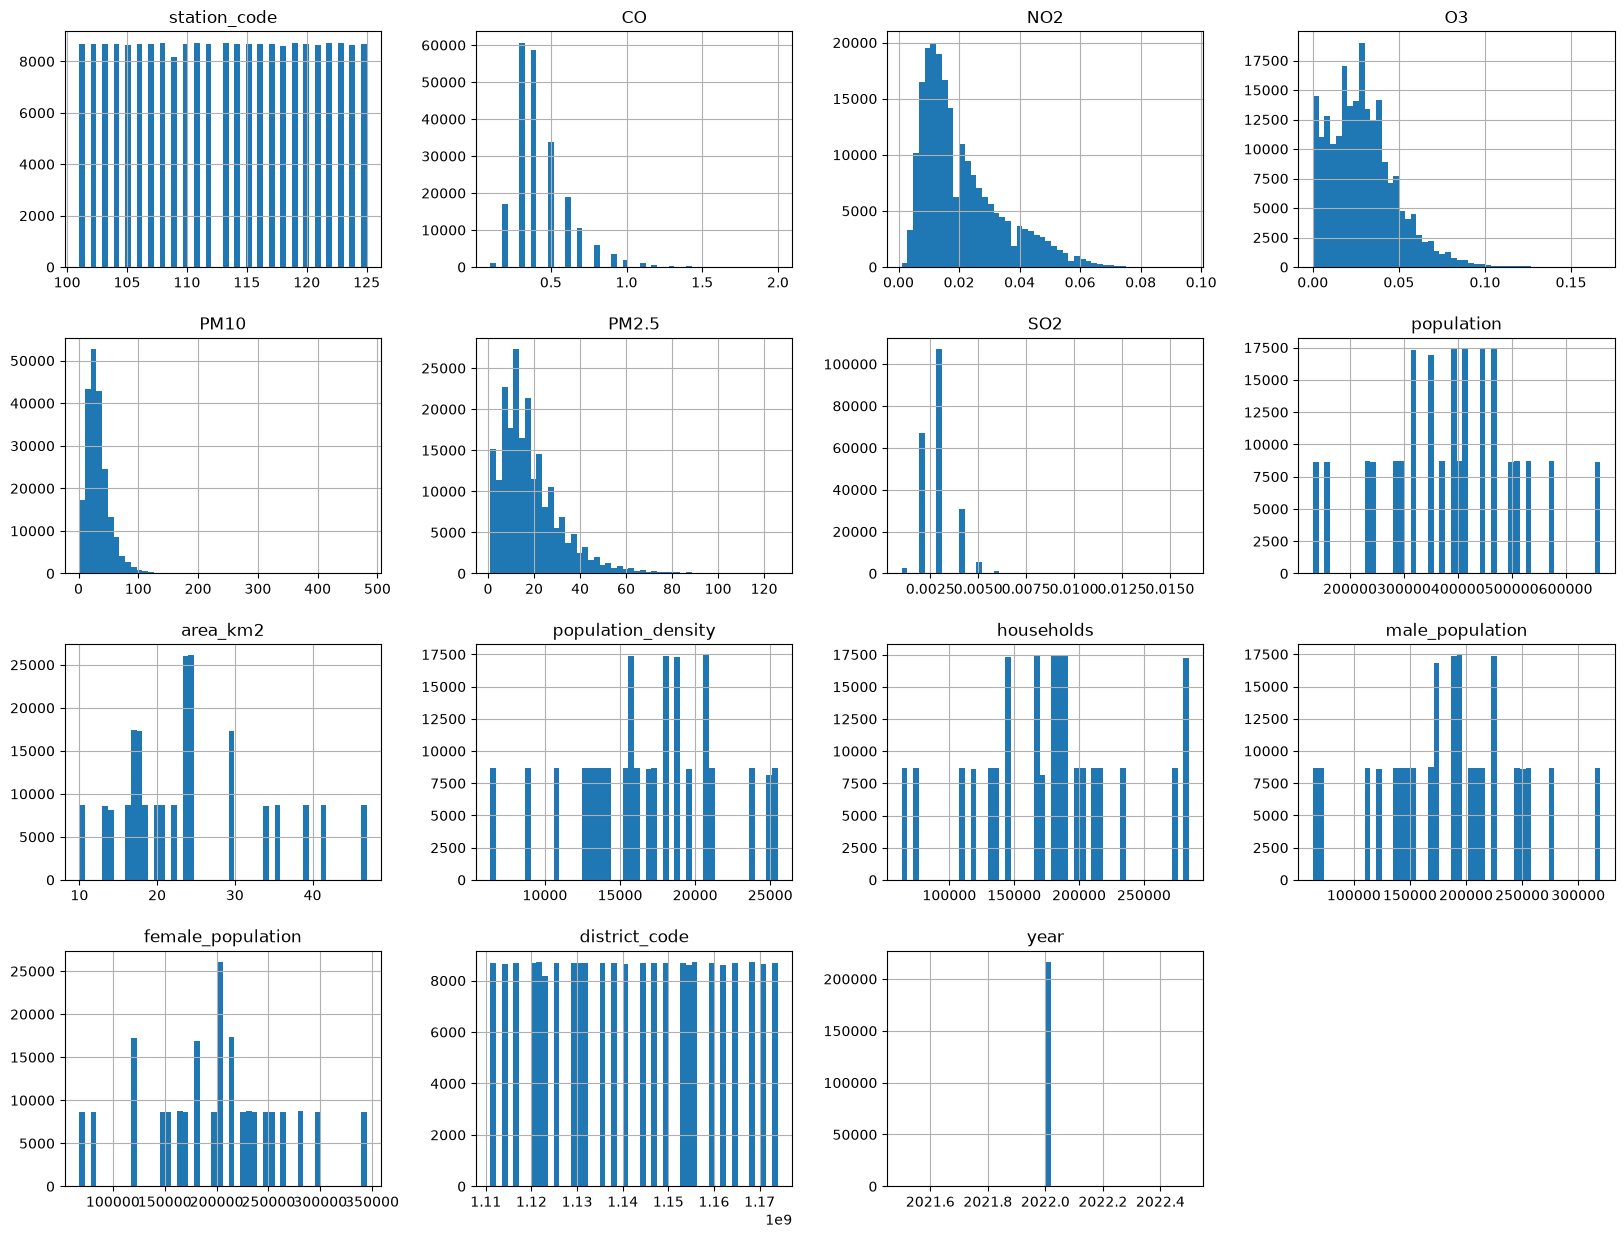

In [5]:
df.hist(bins=50,figsize=(20,15))
plt.show()

Data Profile Table

In [6]:
profile=pd.DataFrame({'Data Type': df_raw.dtypes.astype(str),
                     'Missing Count': df_raw.isnull().sum(),
                     'Missing Percent':df_raw.isnull().sum()*100/len(df_raw),
                     'Unique Values':df_raw.nunique(),
                     'Minimum':df_raw.min(numeric_only=False),
                     'Maximum':df_raw.max(numeric_only=False)})
display(profile)
                     

,Data Type,Missing Count,Missing Percent,Unique Values,Minimum,Maximum
datetime,str,0,0.000000,8760,1/1/2022 0:00,9/9/2022 9:00
station_code,int64,0,0.000000,25,101,125
district,str,0,0.000000,25,Dobong-gu,Yongsan-gu
CO,float64,1403,0.647902,20,0.1,2.0
NO2,float64,1005,0.464107,93,0.001,0.096
O3,float64,1336,0.616962,154,0.0,0.167
PM10,float64,2409,1.112471,359,1.0,482.0
PM2.5,float64,1740,0.803528,124,1.0,126.0
SO2,float64,1706,0.787827,15,0.001,0.016
population,int64,0,0.000000,25,130785,664514


Data Cleaning and Preprocessing

Data Cleaning 
An analysis of data cleaning revealed that pollutants including CO,NO2,O3,PM10,PM2.5,SO2 contained missing value proportion of approximately 0.648%,0.464%,0.617%,
1.11%,0.803%,0.788% respectively.Although the missingness rate is low,the null values were dispered in almost pollutant columns.Moreover,the dataset recorded the air quality
as a continious time series,removing rows with null values can interrupt temporal continuity and cause a loss in a lot of important information and flawed comparison between
districts.To solve this problem,a group median imputation approach was priority.Unlike Vietnam,air quality in Seoul exhibits cyclical pattern driven by hourly variation and distinct 
seasonal characteristics(Spring,Summer,Autumn,Winter).Furthermore,df.describe() and histogram  indicated that the mean value consistently exceeded the median value,proving a right-skewness distribution 
caused by outliers.The reason of these mistakes may be system error...Therefore,the median was selected over the mean as a central tendency measure to fill missing values group by station_code, hour and season


In [7]:
df['datetime']=pd.to_datetime(df['datetime'])
df['hour']=df['datetime'].dt.hour
df['month']=df['datetime'].dt.month
df['date']=df['datetime'].dt.date
pollutants=['CO','NO2','O3','PM10','PM2.5','SO2']
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Spring"
    elif month in [6,7,8]:
        return "Summer"
    else:
        return "Autumn"
df['season']=df['month'].apply(get_season)
for pollutant in pollutants:
    df[pollutant]=df[pollutant].fillna(df.groupby(['station_code','hour','season'])[pollutant].transform('median'))


After the data imputation process,a unit discrepancy was identified among pollutant metrics.While particular matter(PM10,PM2.5) was recorded in micrograms per cubic meter(ug/m^3),the remaining pollutants were measured in parts per million(ppm).To align with international standardization measurement ,the gaseous pollutants were converted to ug/m^3.Rather than overwriting the original columns,these converted values were added into new columns(NO2_ugm3,SO2_ugm3,O3_ugm3,CO_ugm3).This strategy helps to preserve raw data integrity for baseline verification to prepare machine learning model

In [8]:
#unit normalization
df['NO2_ugm3']=df['NO2']*1880
df['SO2_ugm3']=df['SO2']*2620
df['O3_ugm3']=df['O3']*1960
df['CO_ugm3']=df['CO']*1145
display(df[['NO2','NO2_ugm3','SO2','SO2_ugm3']].head())

,NO2,NO2_ugm3,SO2,SO2_ugm3
0,0.016,30.08,0.003,7.86
1,0.024,45.12,0.003,7.86
2,0.020,37.60,0.003,7.86
3,0.019,35.72,0.004,10.48
4,0.020,37.60,0.003,7.86


Check missing values after preparing proccess

In [9]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 216545 entries, 0 to 216544
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   datetime            216545 non-null  datetime64[us]
 1   station_code        216545 non-null  int64         
 2   district            216545 non-null  str           
 3   CO                  216545 non-null  float64       
 4   NO2                 216545 non-null  float64       
 5   O3                  216545 non-null  float64       
 6   PM10                216545 non-null  float64       
 7   PM2.5               216545 non-null  float64       
 8   SO2                 216545 non-null  float64       
 9   population          216545 non-null  int64         
 10  area_km2            216545 non-null  float64       
 11  population_density  216545 non-null  int64         
 12  households          216545 non-null  int64         
 13  male_population     216545 non-null  int

None

In [10]:
hour_count=df.groupby('district').size().reset_index(name='total_hours')
print(hour_count)

           district  total_hours
0         Dobong-gu         8700
1     Dongdaemun-gu         8169
2        Dongjak-gu         8684
3      Eunpyeong-gu         8689
4        Gangbuk-gu         8688
5       Gangdong-gu         8685
6        Gangnam-gu         8708
7        Gangseo-gu         8679
8      Geumcheon-gu         8603
9           Guro-gu         8692
10        Gwanak-gu         8624
11      Gwangjin-gu         8732
12        Jongno-gu         8673
13          Jung-gu         8661
14      Jungnang-gu         8694
15          Mapo-gu         8692
16         Nowon-gu         8695
17        Seocho-gu         8702
18     Seodaemun-gu         8650
19      Seongbuk-gu         8703
20     Seongdong-gu         8695
21        Songpa-gu         8646
22     Yangcheon-gu         8683
23  Yeongdeungpo-gu         8709
24       Yongsan-gu         8689


Cleaning log

In [11]:
cleaning_log=[]
def log_action(Step,Issue,Action,Reason):
    cleaning_log.append({'Step':Step,'Issue':Issue,'Action':Action,'Reason':Reason})
initial_rows=len(df)
log_action(1,'Datetime as String','Convert to Datetime','Enable daily analysis')
log_action(2,'No time features','Create hour,month,date,season','Needed for grouped imputation and daily aggregation')
log_action(3,'Possible duplicates','Checked(district,datetime):0 found','No removal needed')
log_action(4,'Missing value in pollutants(CO,NO2,SO2,O3,PM25,PM10)','Group median imputation','Preserve temporal patterns')
log_action(5,f'Missing timestamps:{25*8760-len(df_raw)} rows','Reported,not imputed','Avoid inventing data; may bias total today')
log_action(6,'Different pollutant units','Convert into standardlizable units','Enable threshold comparisions')
log_action(7,'Outlier(PM10max=482)','Keep as is','Maybe real events,not confirmed errors')
log_action(8,'Hourly Data','Aggregate to daily mean/median per district',"Match WHO's polluted level threshold")
log_action(9,'PM2.5>15,PM10>45,NO2>25ug/m^3','Match WHO 24-hour guideline in 2021','Define standardalizable threshold')
log_df=pd.DataFrame(cleaning_log)
display(log_df)

,Step,Issue,Action,Reason
0,1,Datetime as String,Convert to Datetime,Enable daily analysis
1,2,No time features,"Create hour,month,date,season",Needed for grouped imputation and daily aggreg...
2,3,Possible duplicates,"Checked(district,datetime):0 found",No removal needed
3,4,"Missing value in pollutants(CO,NO2,SO2,O3,PM25...",Group median imputation,Preserve temporal patterns
4,5,Missing timestamps:2455 rows,"Reported,not imputed",Avoid inventing data; may bias total today
5,6,Different pollutant units,Convert into standardlizable units,Enable threshold comparisions
6,7,Outlier(PM10max=482),Keep as is,"Maybe real events,not confirmed errors"
7,8,Hourly Data,Aggregate to daily mean/median per district,Match WHO's polluted level threshold
8,9,"PM2.5>15,PM10>45,NO2>25ug/m^3",Match WHO 24-hour guideline in 2021,Define standardalizable threshold


2455


,district,gap_id,start,end,hours
34,Dongdaemun-gu,35,2022-08-08 18:00:00,2022-08-31 16:00:00,551
279,Gwanak-gu,280,2022-11-11 17:00:00,2022-11-14 17:00:00,73
214,Geumcheon-gu,215,2022-04-02 05:00:00,2022-04-04 11:00:00,55
526,Songpa-gu,527,2022-07-22 17:00:00,2022-07-24 12:00:00,44
223,Geumcheon-gu,224,2022-08-02 11:00:00,2022-08-03 16:00:00,30
126,Gangdong-gu,127,2022-07-14 15:00:00,2022-07-15 20:00:00,30
431,Seodaemun-gu,432,2022-03-07 09:00:00,2022-03-08 14:00:00,30
412,Seocho-gu,413,2022-04-25 14:00:00,2022-04-26 16:00:00,27
469,Seongbuk-gu,470,2022-09-27 13:00:00,2022-09-28 15:00:00,27
6,Dobong-gu,7,2022-04-27 12:00:00,2022-04-28 14:00:00,27


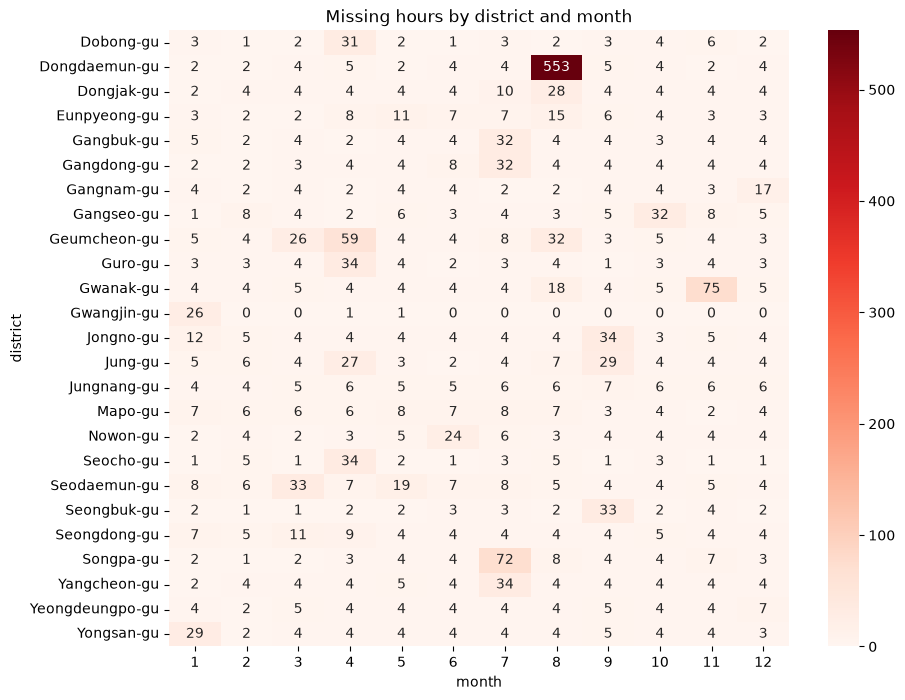

In [12]:

full_idx = pd.date_range('2022-01-01 00:00', '2022-12-31 23:00', freq='h')
full = pd.MultiIndex.from_product(
    [df['district'].unique(), full_idx], names=['district', 'datetime']
).to_frame(index=False)


merged = full.merge(df[['district', 'datetime']].assign(present=1),
                    on=['district', 'datetime'], how='left')
missing_rows = merged[merged['present'].isna()].sort_values(['district', 'datetime'])
print(len(missing_rows))   

gap_id = (missing_rows.groupby('district')['datetime'].diff() != pd.Timedelta(hours=1)).cumsum()
gaps = (missing_rows.assign(gap_id=gap_id)
        .groupby(['district', 'gap_id'])
        .agg(start=('datetime', 'min'), end=('datetime', 'max'), hours=('datetime', 'size'))
        .reset_index())
display(gaps.sort_values('hours', ascending=False).head(10))


missing_rows['month'] = missing_rows['datetime'].dt.month
pivot = missing_rows.pivot_table(index='district', columns='month',
                                 values='datetime', aggfunc='size', fill_value=0)
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, annot=True, fmt='d', cmap='Reds')
plt.title('Missing hours by district and month')
plt.show()

Explotary Data Analysis

In [13]:

daily_df=df.groupby(['district','date']).agg(
    PM25_median=('PM2.5','median'),
    PM10_median=('PM10','median'),
    NO2_median=('NO2_ugm3','median'),
    PM25_mean=('PM2.5', 'mean'),
    PM10_mean=('PM10', 'mean'),
    NO2_mean=('NO2_ugm3', 'mean'),
    population=('population','first'),
    po_density=('population_density','first'),
    area=('area_km2','first')
).reset_index()

district_median = daily_df.groupby('district').agg(
    PM25_typical=('PM25_median', 'median'),
    PM10_typical=('PM10_median', 'median'),
    NO2_typical=('NO2_median', 'median')
).reset_index()


display(district_median)
pollution=daily_df[(daily_df['PM25_mean']>15)|(daily_df['PM10_mean']>45)|(daily_df['NO2_mean']>25)]
district_summary=pollution.groupby(['district']).agg(
    total_days=('date','count'),
    district_population=('population','first'),
    district_popdens=('po_density','first'),
    dis_area=('area','first')
).reset_index()

pm25_q75 = district_median['PM25_typical'].quantile(0.75)
top_pm25 = district_median[
    district_median['PM25_typical'] >= pm25_q75
].sort_values('PM25_typical', ascending=False)
display(top_pm25)

pm10_q75 = district_median['PM10_typical'].quantile(0.75)
top_pm10 = district_median[
    district_median['PM10_typical'] >= pm10_q75
].sort_values('PM10_typical', ascending=False)
display(top_pm10)

no2_q75 = district_median['NO2_typical'].quantile(0.75)
top_no2 = district_median[
    district_median['NO2_typical'] >= no2_q75
].sort_values('NO2_typical', ascending=False)
display(top_no2)

#Q3 seoul
hazard_q75=district_summary['total_days'].quantile(0.75)
serious_pollution=district_summary[district_summary['total_days']>=hazard_q75]
serious_pollution=serious_pollution.sort_values(by='total_days',ascending=False)
print(f'polluted days in Seoul: {hazard_q75} days')
display(serious_pollution)

#Demographic Exposure
dens_seoul=district_summary['district_popdens'].quantile(0.75)
pop_seoul=district_summary['district_population'].quantile(0.75)
area_q75=district_summary['dis_area'].quantile(0.75)
filtered_district=district_summary[(district_summary['total_days']>=hazard_q75)&(district_summary['district_popdens']>=dens_seoul)]
display(filtered_district)

#Area Filter
med_seoularea=district_summary['dis_area'].median()
filtered_area=district_summary.query('dis_area>@med_seoularea')
display(filtered_area)

,district,PM25_typical,PM10_typical,NO2_typical
0,Dobong-gu,13.5,24.0,21.62
1,Dongdaemun-gu,15.5,29.5,31.02
2,Dongjak-gu,16.0,30.0,31.02
3,Eunpyeong-gu,16.0,27.0,25.38
4,Gangbuk-gu,15.0,30.0,20.68
5,Gangdong-gu,15.0,29.0,30.08
6,Gangnam-gu,14.0,27.5,36.66
7,Gangseo-gu,14.5,31.0,31.96
8,Geumcheon-gu,15.0,26.5,35.72
9,Guro-gu,12.0,30.5,29.14


,district,PM25_typical,PM10_typical,NO2_typical
16,Nowon-gu,17.0,29.0,28.20
22,Yangcheon-gu,16.5,29.0,31.02
24,Yongsan-gu,16.0,29.5,33.84
2,Dongjak-gu,16.0,30.0,31.02
3,Eunpyeong-gu,16.0,27.0,25.38
12,Jongno-gu,16.0,27.5,31.02
1,Dongdaemun-gu,15.5,29.5,31.02
13,Jung-gu,15.5,26.0,38.54
21,Songpa-gu,15.5,29.5,35.72


,district,PM25_typical,PM10_typical,NO2_typical
7,Gangseo-gu,14.5,31.0,31.96
9,Guro-gu,12.0,30.5,29.14
4,Gangbuk-gu,15.0,30.0,20.68
2,Dongjak-gu,16.0,30.0,31.02
20,Seongdong-gu,13.5,30.0,32.90
1,Dongdaemun-gu,15.5,29.5,31.02
21,Songpa-gu,15.5,29.5,35.72
24,Yongsan-gu,16.0,29.5,33.84


,district,PM25_typical,PM10_typical,NO2_typical
13,Jung-gu,15.5,26.0,38.54
6,Gangnam-gu,14.0,27.5,36.66
8,Geumcheon-gu,15.0,26.5,35.72
21,Songpa-gu,15.5,29.5,35.72
10,Gwanak-gu,15.0,29.0,34.78
15,Mapo-gu,14.0,25.0,34.78
19,Seongbuk-gu,15.0,28.0,34.78
23,Yeongdeungpo-gu,14.5,28.0,34.78


polluted days in Seoul: 309.0 days


,district,total_days,district_population,district_popdens,dis_area
13,Jung-gu,323,130785,13131,9.96
6,Gangnam-gu,318,534103,13522,39.50
23,Yeongdeungpo-gu,318,398085,16215,24.55
19,Seongbuk-gu,313,441984,17983,24.58
21,Songpa-gu,311,664514,19616,33.88
15,Mapo-gu,310,375585,15745,23.85
10,Gwanak-gu,309,501226,16951,29.57


,district,total_days,district_population,district_popdens,dis_area
21,Songpa-gu,311,664514,19616,33.88


,district,total_days,district_population,district_popdens,dis_area
3,Eunpyeong-gu,265,470602,15838,29.71
5,Gangdong-gu,273,464037,18871,24.59
6,Gangnam-gu,318,534103,13522,39.50
7,Gangseo-gu,298,574638,13862,41.45
10,Gwanak-gu,309,501226,16951,29.57
12,Jongno-gu,292,152211,6365,23.91
15,Mapo-gu,310,375585,15745,23.85
16,Nowon-gu,282,508014,14335,35.44
17,Seocho-gu,294,408451,8696,46.97
19,Seongbuk-gu,313,441984,17983,24.58


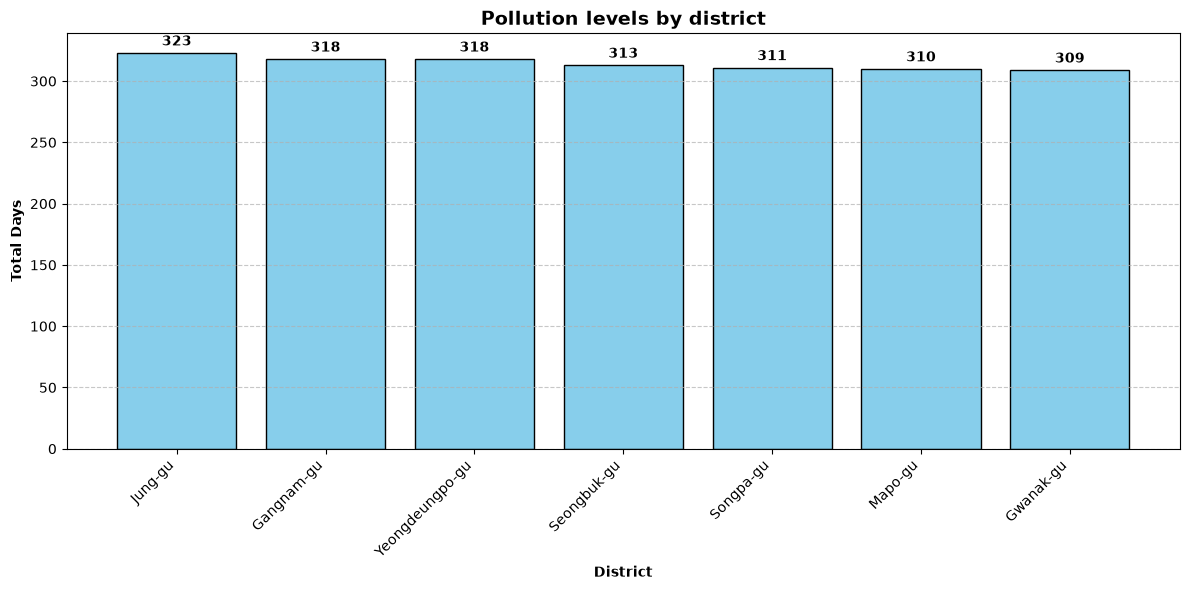

In [41]:

fig,ax=plt.subplots(figsize=(12,6))
bar=ax.bar(serious_pollution['district'],serious_pollution['total_days'],color='skyblue',edgecolor='black')
ax.bar_label(bar,padding=3,fontsize=10,fontweight='bold')
ax.set_title('Pollution levels by district',fontsize=14,fontweight='bold')
ax.set_xlabel('District',fontsize=10,fontweight='bold')
ax.set_ylabel('Total Days',fontsize=10,fontweight='bold')
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

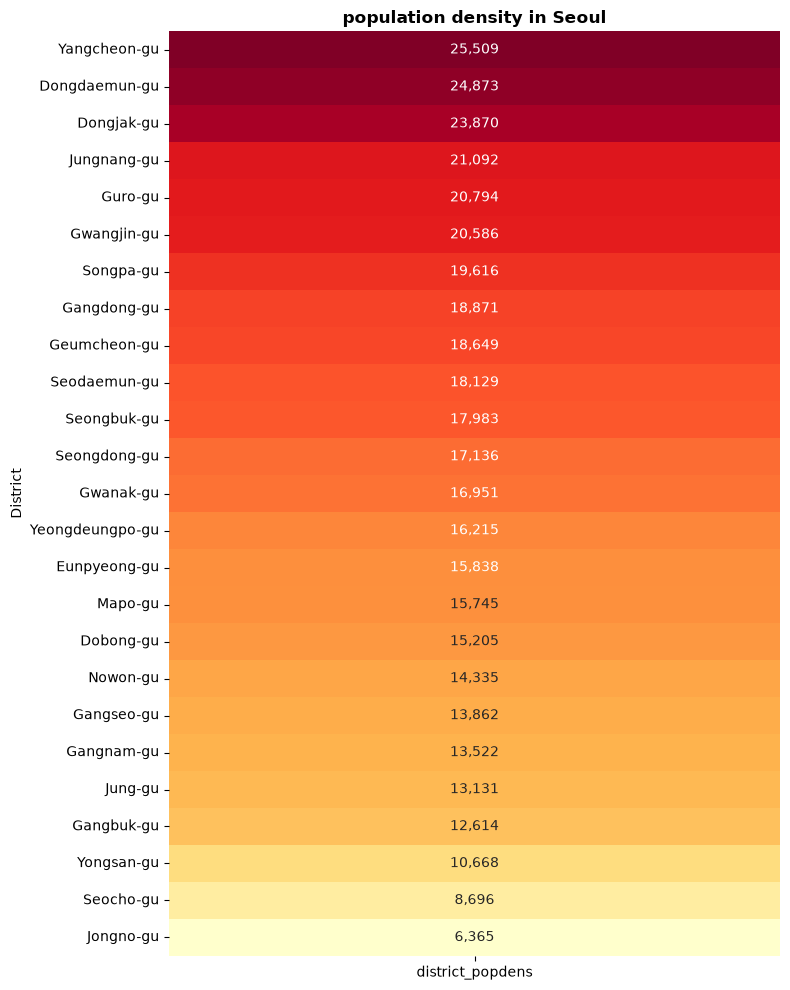

In [15]:
daily_sorted=district_summary.sort_values(by='district_popdens',ascending=False).set_index('district')
plt.figure(figsize=(8,10))
sns.heatmap(daily_sorted[['district_popdens']],annot=True,fmt=',.0f',cmap='YlOrRd',cbar=False)
plt.title('population density in Seoul',fontsize=12,fontweight='bold')
plt.ylabel('District')
plt.tight_layout()
plt.show()

In [16]:
!pip install adjustText
from adjustText import adjust_text


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


The goal of this project is to visualize the total pollution-exceeding days across the 25 districts  of Seoul in relation to population data,identifying the districts facing severe health risks to strategically determine optimal locations for new air quality monitoring station

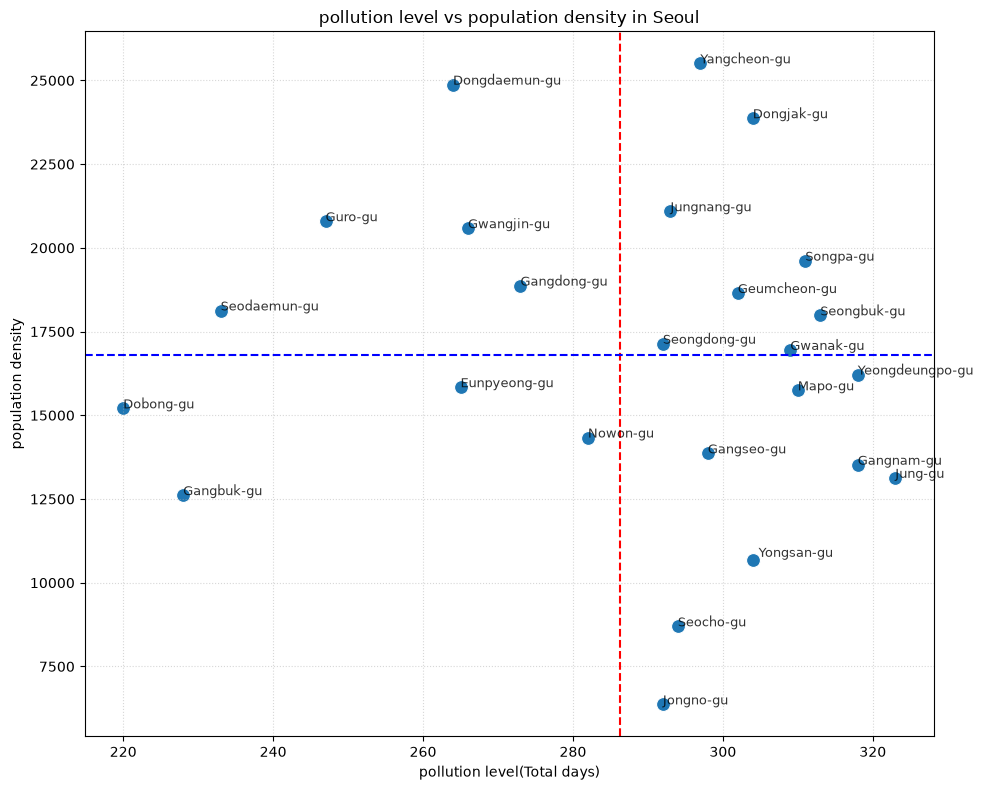

In [17]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=district_summary.reset_index(),x='total_days',y='district_popdens',s=100,legend=False)
mean_day=district_summary['total_days'].mean()
mean_pop=district_summary['district_popdens'].mean()
plt.axvline(mean_day,color='red',linestyle='--')
plt.axhline(mean_pop,color='blue',linestyle='--')
texts=[]
for i in range(len(district_summary)):
      t=plt.text(district_summary['total_days'].iloc[i],
            district_summary['district_popdens'].iloc[i],
            district_summary['district'].iloc[i],
            fontsize=9,
            alpha=0.8)
texts.append(t)
adjust_text(texts,arrowprops=dict(arrowstyle='-',color='gray',lw=0.5))
plt.title('pollution level vs population density in Seoul')
plt.xlabel('pollution level(Total days)')
plt.ylabel('population density')
plt.grid(True,linestyle=':',alpha=0.5)
plt.tight_layout()
plt.show()

Statistic Analysis

In [18]:
stats_result=df.groupby(['district','month']).agg({'PM2.5':['mean','median','std',lambda x:x.quantile(0.9)],'PM10':['mean','median','std',lambda x:x.quantile(0.9)],
                                                   'NO2':['mean','median','std',lambda x:x.quantile(0.9)],'CO':['mean','median','std',lambda x:x.quantile(0.9)]})
stats_result.columns=['_'.join(col).strip() for col in stats_result.columns.values]
stats_result=stats_result.reset_index()
print(stats_result.head())

    district  month  PM2.5_mean  PM2.5_median  PM2.5_std  PM2.5_<lambda_0>  \
0  Dobong-gu      1   28.097166          23.0  19.102816              49.0   
1  Dobong-gu      2   25.248882          18.0  18.534495              52.0   
2  Dobong-gu      3   21.953504          17.0  16.396082              45.0   
3  Dobong-gu      4   21.400581          21.0  12.909425              39.0   
4  Dobong-gu      5   15.880054          14.0   9.957557              27.0   

   PM10_mean  PM10_median   PM10_std  PM10_<lambda_0>  NO2_mean  NO2_median  \
0  44.373819         39.0  21.933051             69.0  0.025240      0.0220   
1  38.272727         33.0  20.658239             66.0  0.019869      0.0140   
2  39.078167         33.0  30.178215             71.0  0.020363      0.0175   
3  41.330914         39.0  28.965260             65.2  0.016025      0.0130   
4  31.721698         30.0  15.518253             50.0  0.011472      0.0100   

    NO2_std  NO2_<lambda_0>   CO_mean  CO_median    CO_s

In [19]:
#Correlation between population density and PM2.5
corr_matrix=df[['population_density','population','CO','NO2','O3','PM2.5','PM10']].corr()
print(corr_matrix)
correlation=df['population_density'].corr(df['PM2.5'])
display(correlation)

                    population_density  population        CO       NO2  \
population_density            1.000000    0.293346 -0.010590  0.003569   
population                    0.293346    1.000000  0.013441  0.036016   
CO                           -0.010590    0.013441  1.000000  0.739925   
NO2                           0.003569    0.036016  0.739925  1.000000   
O3                           -0.018150   -0.030800 -0.359378 -0.515450   
PM2.5                         0.011498    0.002968  0.626794  0.495888   
PM10                          0.022761    0.037727  0.443375  0.368668   

                          O3     PM2.5      PM10  
population_density -0.018150  0.011498  0.022761  
population         -0.030800  0.002968  0.037727  
CO                 -0.359378  0.626794  0.443375  
NO2                -0.515450  0.495888  0.368668  
O3                  1.000000 -0.002412  0.050138  
PM2.5              -0.002412  1.000000  0.768416  
PM10                0.050138  0.768416  1.000000  

np.float64(0.011497504800205817)

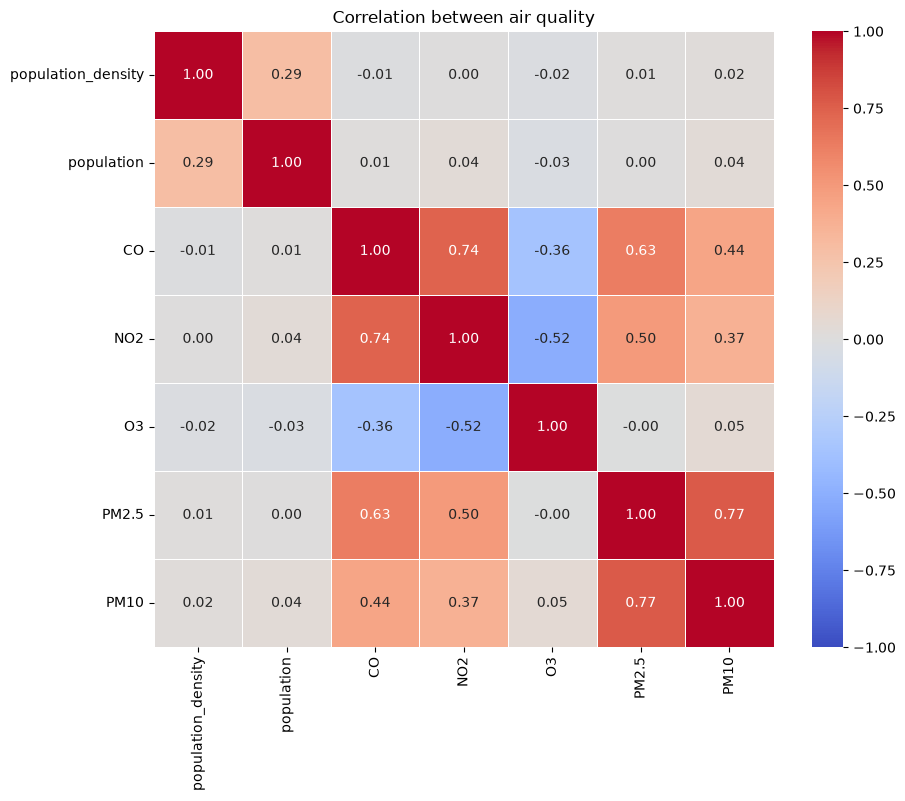

In [20]:
plt.figure(figsize=(10,8))
sns.heatmap(data=corr_matrix,
           annot=True,
           cmap='coolwarm',
           fmt='.2f',
           linewidths=0.5,
           cbar=True,
           vmin=-1,vmax=1)
plt.title("Correlation between air quality")
plt.show()

# Step 3.2 - Exploratory Data Visualization

## Visualization Lead

### Chart 1: Monthly PM2.5 Trend in Seoul (2022)
#### How does the average PM2.5 concentration in Seoul change from January to December 2022?

In [21]:
#Data Validation / Data Inspection
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df[['datetime', 'district', 'month', 'PM2.5']].head())

print("\nMissing PM2.5:")
print(df['PM2.5'].isna().sum())


Dataset shape: (216545, 25)

Columns:
    datetime      district  month  PM2.5
0 2022-01-01     Jongno-gu      1   12.0
1 2022-01-01       Jung-gu      1   10.0
2 2022-01-01    Yongsan-gu      1   13.0
3 2022-01-01  Eunpyeong-gu      1   10.0
4 2022-01-01  Seodaemun-gu      1   13.0

Missing PM2.5:
0


In [22]:
## Calculate average PM2.5 for each district and month
district_monthly = (df.groupby(['district','month'])['PM2.5'].mean().reset_index(name='avg_pm25'))
display(district_monthly.head())


,district,month,avg_pm25
0,Dobong-gu,1,28.097166
1,Dobong-gu,2,25.248882
2,Dobong-gu,3,21.953504
3,Dobong-gu,4,21.400581
4,Dobong-gu,5,15.880054


In [23]:
#check after calculate average PM2.5 for each district and month
print("Shape:", district_monthly.shape)
print("Number of districts:", district_monthly['district'].nunique())
print("Number of months:", district_monthly['month'].nunique())
print("Missing averages:", district_monthly['avg_pm25'].isna().sum())

Shape: (300, 3)
Number of districts: 25
Number of months: 12
Missing averages: 0


In [24]:
##Calculate average PM2.5 for each month 
monthly_pm25 = (district_monthly.groupby(['month'])['avg_pm25'].mean().reset_index())
display(monthly_pm25.head())

,month,avg_pm25
0,1,28.697891
1,2,25.487815
2,3,21.156026
3,4,21.742372
4,5,16.845483


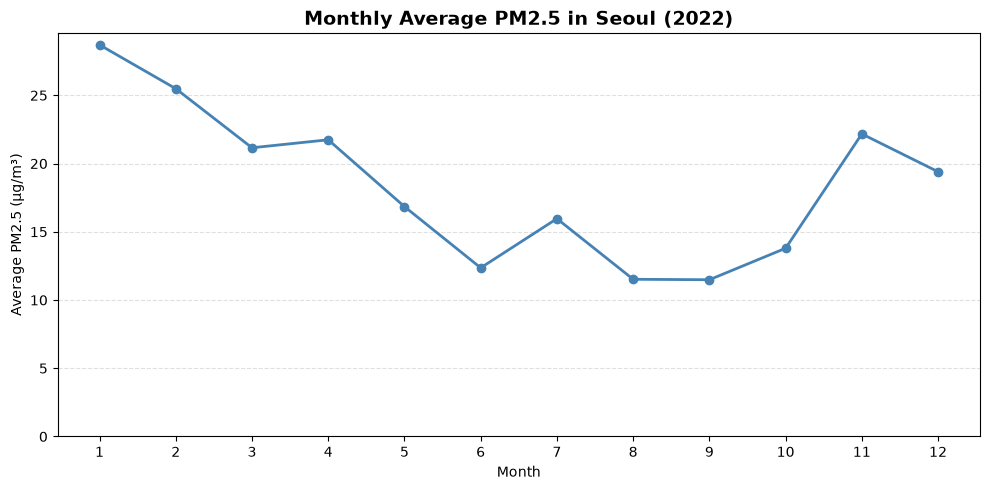

In [25]:

# Chart 1 - Line chart: Monthly PM2.5 Trend in Seoul

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_pm25['month'],
    monthly_pm25['avg_pm25'],
    marker='o',
    color='steelblue',
    linewidth=2,
    markersize=6
)

ax.set_title(
    'Monthly Average PM2.5 in Seoul (2022)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Month')
ax.set_ylabel('Average PM2.5 (µg/m³)')

ax.set_xticks(range(1, 13))
ax.set_ylim(bottom=0)

ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


In [26]:
print("Shape:", monthly_pm25.shape)
print("Unique months:", monthly_pm25['month'].nunique())
print("Missing values:")
print(monthly_pm25.isna().sum())
display(monthly_pm25.sort_values('month'))


Shape: (12, 2)
Unique months: 12
Missing values:
month       0
avg_pm25    0
dtype: int64


,month,avg_pm25
0,1,28.697891
1,2,25.487815
2,3,21.156026
3,4,21.742372
4,5,16.845483
5,6,12.358544
6,7,15.961750
7,8,11.520690
8,9,11.486134
9,10,13.793450


In [27]:
district_count = (district_monthly.groupby('month')['district'].nunique())
display(district_count)


month
1     25
2     25
3     25
4     25
5     25
6     25
7     25
8     25
9     25
10    25
11    25
12    25
Name: district, dtype: int64

In [28]:
#Which month recorded the highest average PM2.5 concentration?
highest_month = monthly_pm25.loc[monthly_pm25['avg_pm25'].idxmax()]
print(highest_month)


month        1.000000
avg_pm25    28.697891
Name: 0, dtype: float64


In [29]:
#Which month recorded the lowest average PM2.5 concentration?
lowest_month = monthly_pm25.loc[monthly_pm25['avg_pm25'].idxmin()]
print(lowest_month)

month        9.000000
avg_pm25    11.486134
Name: 8, dtype: float64


# Chart 2: Bar Chart: Compare average pollution levels across 25 districts
### How does the average PM2.5 concentration in Seoul change from January to December 2022?

In [30]:
# Average PM2.5 concentration by district
district_pm25 = (df.groupby('district')['PM2.5'].mean().reset_index(name='avg_pm25'))
display(district_pm25.head())


,district,avg_pm25
0,Dobong-gu,16.930747
1,Dongdaemun-gu,19.199229
2,Dongjak-gu,20.227142
3,Eunpyeong-gu,19.083727
4,Gangbuk-gu,18.321133


In [31]:
# Sort the descending values (from the highest values to the lowest values)
district_pm25 = district_pm25.sort_values('avg_pm25', ascending=False)
display(district_pm25.head(10))


,district,avg_pm25
16,Nowon-gu,20.446866
22,Yangcheon-gu,20.227744
2,Dongjak-gu,20.227142
13,Jung-gu,19.305738
12,Jongno-gu,19.276894
1,Dongdaemun-gu,19.199229
3,Eunpyeong-gu,19.083727
24,Yongsan-gu,18.872482
5,Gangdong-gu,18.838400
8,Geumcheon-gu,18.564338


In [32]:
#Validate PM2.5
print("Shape:", district_pm25.shape)
print("Number of districts:", district_pm25['district'].nunique())

print("Missing values:", district_pm25['avg_pm25'].isna().sum())


Shape: (25, 2)
Number of districts: 25
Missing values: 0


In [33]:
print("Sorted descending:", district_pm25['avg_pm25'].is_monotonic_decreasing)

Sorted descending: True


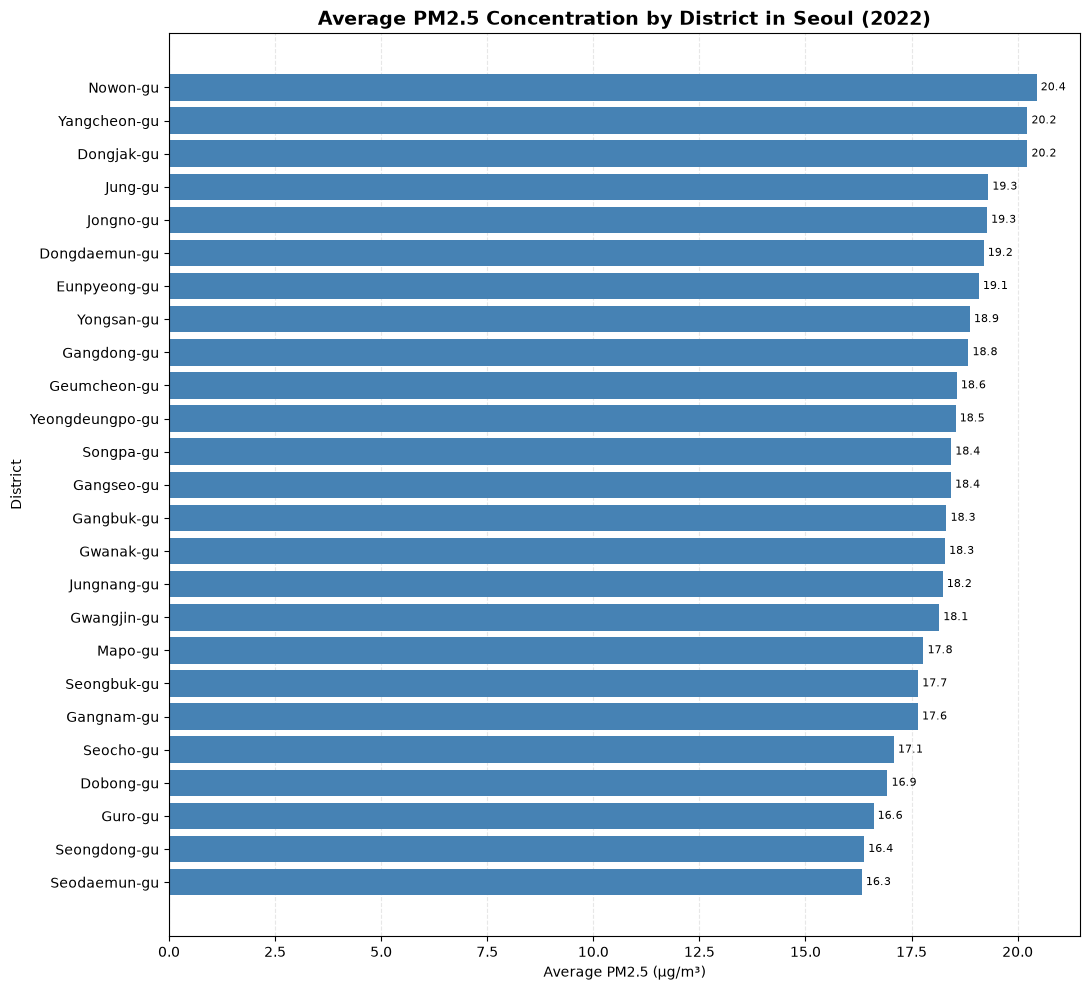

In [34]:
# Chart 2: Average PM2.5 by District in Seoul
fig, ax = plt.subplots(figsize=(11, 10))

bars = ax.barh(
    district_pm25['district'],
    district_pm25['avg_pm25'],
    color='steelblue'
)

# Highest concentration at the top
ax.invert_yaxis()

# Title and axis labels
ax.set_title('Average PM2.5 Concentration by District in Seoul (2022)', fontsize=14, fontweight='bold')

ax.set_xlabel('Average PM2.5 (µg/m³)')
ax.set_ylabel('District')

# Start the value axis at zero
ax.set_xlim(left=0)

# Display values
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

# Grid
ax.grid( axis='x', linestyle='--', alpha=0.3 )
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [35]:
#Validate Bar Chart
print("Number of bars:", len(bars))

highest_district = district_pm25.iloc[0]
lowest_district = district_pm25.iloc[-1]

print("Highest PM2.5:")
print(highest_district)

print("\nLowest PM2.5:")
print(lowest_district)


Number of bars: 25
Highest PM2.5:
district     Nowon-gu
avg_pm25    20.446866
Name: 16, dtype: object

Lowest PM2.5:
district    Seodaemun-gu
avg_pm25       16.326301
Name: 18, dtype: object


# Chart 3: Scatter Plot + Trendline: Relationship between Population Density (X) and Pollution (Y).
### Is there a relationship between population density and average PM2.5 concentration across Seoul's 25 districts?

In [36]:
#check whether the population density is fixed
df.loc[
    df['district'] == 'Gangnam-gu',
    ['datetime', 'district', 'PM2.5', 'population_density']
].head(10)


,datetime,district,PM2.5,population_density
22,2022-01-01 00:00:00,Gangnam-gu,9.0,13522
47,2022-01-01 01:00:00,Gangnam-gu,8.0,13522
72,2022-01-01 02:00:00,Gangnam-gu,7.0,13522
97,2022-01-01 03:00:00,Gangnam-gu,7.0,13522
122,2022-01-01 04:00:00,Gangnam-gu,11.0,13522
147,2022-01-01 05:00:00,Gangnam-gu,9.0,13522
172,2022-01-01 06:00:00,Gangnam-gu,9.0,13522
197,2022-01-01 07:00:00,Gangnam-gu,11.0,13522
222,2022-01-01 08:00:00,Gangnam-gu,12.0,13522
247,2022-01-01 09:00:00,Gangnam-gu,10.0,13522


In [37]:
# Population density for each district
population_density_by_district = (
    df.groupby('district')['population_density']
    .first()
    .reset_index()
)

display(population_density_by_district.head())


,district,population_density
0,Dobong-gu,15205
1,Dongdaemun-gu,24873
2,Dongjak-gu,23870
3,Eunpyeong-gu,15838
4,Gangbuk-gu,12614


In [38]:
# Merge PM2.5 and population density by district
scatter_df = pd.merge(
    district_pm25,
    population_density_by_district,
    on='district',
    how='inner',
    validate='one_to_one'
)

display(scatter_df.head())


,district,avg_pm25,population_density
0,Nowon-gu,20.446866,14335
1,Yangcheon-gu,20.227744,25509
2,Dongjak-gu,20.227142,23870
3,Jung-gu,19.305738,13131
4,Jongno-gu,19.276894,6365


In [39]:
#Validate scatter_df - Check whether the merge operation results in the loss or duplication of rows.
print("Shape:", scatter_df.shape)
print(
    "Number of districts:",
    scatter_df['district'].nunique()
)

print("\nMissing values:")
print(scatter_df.isna().sum())


Shape: (25, 3)
Number of districts: 25

Missing values:
district              0
avg_pm25              0
population_density    0
dtype: int64


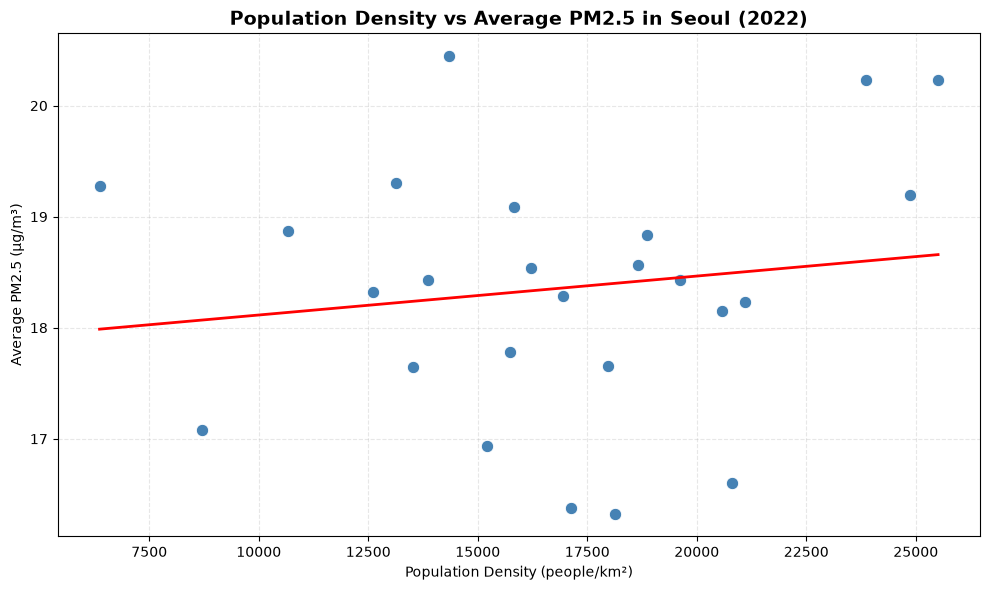

In [40]:
# Chart 3: Population Density vs Average PM2.5

fig, ax = plt.subplots(figsize=(10, 6))

# Scatter Plot
sns.scatterplot(
    data=scatter_df,
    x='population_density',
    y='avg_pm25',
    s=80,
    color='steelblue',
    ax=ax
)

# Trendline
sns.regplot(
    data=scatter_df,
    x='population_density',
    y='avg_pm25',
    scatter=False,
    ci=None,
    color='red',
    line_kws={'linewidth': 2},
    ax=ax
)

ax.set_title(
    'Population Density vs Average PM2.5 in Seoul (2022)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Population Density (people/km²)')
ax.set_ylabel('Average PM2.5 (µg/m³)')

ax.grid(linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
